In [2]:
# ============================================================================
# UNIFIED SCRIPT: Petrecca FFT Stacking, Bending Power-Law Fit & F_var
# ============================================================================

import os
import glob
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from astropy.timeseries import LombScargle
import warnings

warnings.filterwarnings('ignore')

In [3]:
# ---------------------- 1. INITIAL CONFIGURATIONS ----------------------
base_dir = r"ztffp_final_data_2025" 
csv_meta_path = r"Cross_15_luiz.csv"
band = 'g' # Focusing on the g band to avoid emission line contamination
plots_dir_base = "plots_Petrecca_Analysis"
os.makedirs(plots_dir_base, exist_ok=True)

# Grid and Frequency Parameters
MIN_CADENCE_DAYS = 1.0 
f_max_nyquist = 1.0 / (2.0 * MIN_CADENCE_DAYS) 

mass_edges = [7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0]
edd_edges  = [-2.5, -2.0, -1.5, -1.0, -0.5, 0.0]

# Bending Power-Law Function (Petrecca et al.)
def log_bending_power_law(f, logA, log_f_break, alpha, logC):
    f_break = 10**log_f_break
    A = 10**logA
    C = 10**logC
    P = A / (1.0 + (f / f_break)**alpha) + C
    return np.log10(P)

Lendo metadados e processando curvas de luz...


Calculando LS e FFT: 100%|██████████| 464/464 [00:01<00:00, 396.38it/s]



Gerando Plot de Comparação de Leakage...
Ajustando o Bending Power-Law e plotando Grid...
Track log(L/M) ~ -12.0 -> fb: 3.14e-04 day^-1 | tau_b: 8.71 years
Track log(L/M) ~ -11.5 -> fb: 3.16e-05 day^-1 | tau_b: 86.58 years
Track log(L/M) ~ -11.0 -> fb: 4.06e-04 day^-1 | tau_b: 6.74 years
Track log(L/M) ~ -10.5 -> fb: 2.57e-04 day^-1 | tau_b: 10.64 years
Track log(L/M) ~ -10.0 -> fb: 3.16e-05 day^-1 | tau_b: 86.58 years
Track log(L/M) ~ -9.5 -> fb: 3.16e-05 day^-1 | tau_b: 86.58 years
Track log(L/M) ~ -9.0 -> fb: 5.37e-04 day^-1 | tau_b: 5.09 years
Track log(L/M) ~ -8.5 -> fb: 8.57e-05 day^-1 | tau_b: 31.95 years
Track log(L/M) ~ -8.0 -> fb: 3.53e-05 day^-1 | tau_b: 77.59 years


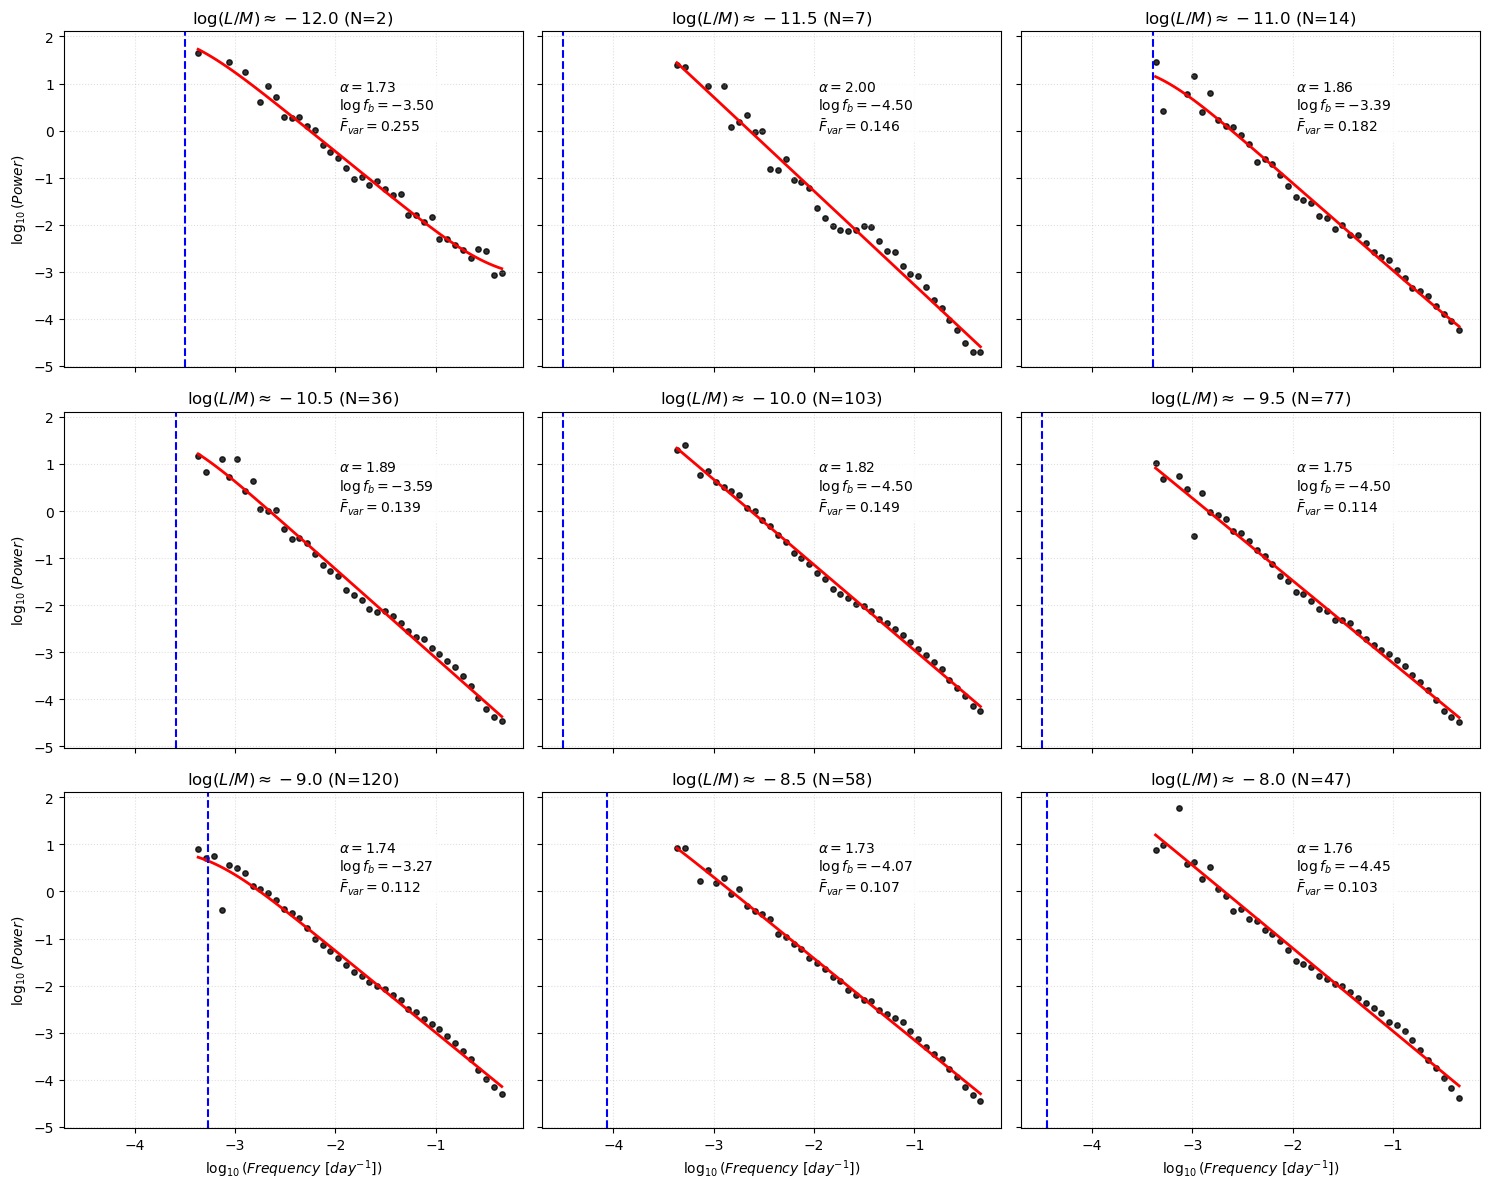


Processamento Finalizado com Sucesso! Gráficos salvos na pasta: plots_Petrecca_Analysis


In [4]:
# ---------------------- 2. READING AND PROCESSING ----------------------
print("Lendo metadados e processando curvas de luz...")
meta = pd.read_csv(csv_meta_path.replace("\\", "/"))
ra_cat, dec_cat = meta['RA'].values, meta['DEC'].values
logmbh_cat, logedd_cat = meta['LOGMBH'].values, meta['LOGLEDD_RATIO'].values

folders = [f for f in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, f)) and "plots" not in f]
valid_data = []

for folder in tqdm(folders, desc="Calculando F_var e Interpolando"):
    try: ra_f, dec_f = map(float, folder.split('_'))
    except: continue
    
    dist = np.sqrt((ra_cat - ra_f)**2 + (dec_cat - dec_f)**2)
    idx = np.argmin(dist)
    if dist[idx] > 1e-4: continue
    
    m, e = logmbh_cat[idx], logedd_cat[idx]
    if np.isnan(m) or np.isnan(e): continue
    if m < mass_edges[0] or m >= mass_edges[-1]: continue
    if e < edd_edges[0] or e >= edd_edges[-1]: continue

    txt_files = glob.glob(os.path.join(base_dir, folder, f"*_ztf_{band}_filtered.txt"))
    if not txt_files: continue
    
    try:
        # Read light curve 
        df = pd.read_csv(txt_files[0])
        
        # --- ADJUST THE COLUMN NAMES HERE ACCORDING TO YOUR FILE ---
        col_t = 'mjd'
        col_f = 'flux'      
        col_e = 'fluxe'     # Replace with the real error name
        
        # Check if the main columns exist
        if len(df) < 10 or col_t not in df.columns or col_f not in df.columns: 
            continue
            
        df['mjd_int'] = np.floor(df[col_t]).astype(int)
        
        # Take the daily mean of time, flux, and error
        df_daily = df.groupby('mjd_int').agg({
            col_t: 'mean', 
            col_f: 'mean', 
            col_e: 'mean'
        }).reset_index()
        
        if len(df_daily) < 10: continue
        
        t = df_daily[col_t].values
        flux = df_daily[col_f].values
        flux_err = df_daily[col_e].values
        
        # --- Cálculo Rigoroso do F_var e Erro (Vaughan et al. 2003) ---
        mean_flux = np.mean(flux)
        S2 = np.var(flux, ddof=1)
        err2 = np.mean(flux_err**2)
        N = len(flux)
        
        if S2 > err2:
            f_var = np.sqrt(S2 - err2) / mean_flux
            
            # Propagação de erro analítica
            term1 = np.sqrt(1.0 / (2.0 * N)) * (err2 / (mean_flux**2 * f_var))
            term2 = np.sqrt(err2 / N) * (1.0 / mean_flux)
            f_var_err = np.sqrt(term1**2 + term2**2)
        else:
            f_var = np.nan 
            f_var_err = np.nan 
            
    except Exception as error: 
        continue
    
    T = t.max() - t.min()
    valid_data.append({
        't': t, 'flux': flux, 'T': T, 
        'f_var': f_var, 'f_var_err': f_var_err,
        'LOGMBH': m, 'LOGLEDD_RATIO': e
    })

if not valid_data:
    raise ValueError("Nenhum dado válido encontrado. Verifique os caminhos.")

# ---------------------- Define Global Frequency Grid (LOGARITHMIC SPACING) ----------------------
T_max = max([d['T'] for d in valid_data])
global_fmin = 1.0 / T_max

# Bins setup
N_bins = 40 
bin_edges = np.logspace(np.log10(global_fmin), np.log10(f_max_nyquist), N_bins + 1)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])

binned_matrix_ls = np.full((len(valid_data), N_bins), np.nan)
binned_matrix_fft = np.full((len(valid_data), N_bins), np.nan)

# ---------------------- 3. PSD: LOMB-SCARGLE VS PETRECCA (FFT) ----------------------
for i, d in enumerate(tqdm(valid_data, desc="Calculando LS e FFT")):
    t_raw, flux_raw = d['t'], d['flux']
    y_norm = (flux_raw - np.median(flux_raw)) / np.median(flux_raw)
    
    # Traditional LS
    ls = LombScargle(t_raw - t_raw.min(), y_norm)
    f_ls, p_ls = ls.autopower(normalization='psd', maximum_frequency=f_max_nyquist)
    
    # Petrecca FFT
    T_total = t_raw.max() - t_raw.min()
    N_pts = int(np.ceil(T_total / MIN_CADENCE_DAYS))
    t_reg = np.linspace(t_raw.min(), t_raw.max(), N_pts)
    
    y_intp = interp1d(t_raw, y_norm, kind='linear', bounds_error=False, fill_value="extrapolate")(t_reg)
    fft_res = np.fft.rfft(y_intp)
    f_fft = np.fft.rfftfreq(N_pts, d=MIN_CADENCE_DAYS)[1:]
    p_fft = ((np.abs(fft_res)**2) * (2.0 * MIN_CADENCE_DAYS / N_pts))[1:]
    
    # Simulated Binning
    for f_arr, p_arr, out_matrix in zip([f_ls, f_fft], [p_ls, p_fft], [binned_matrix_ls, binned_matrix_fft]):
        inds = np.searchsorted(bin_edges, f_arr, side='right') - 1
        valid_mask = (inds >= 0) & (inds < N_bins)
        if np.any(valid_mask):
            bid, pw = inds[valid_mask], p_arr[valid_mask]
            sums = np.bincount(bid, weights=pw, minlength=N_bins)
            counts = np.bincount(bid, minlength=N_bins)
            mask = counts > 0
            out_matrix[i, mask] = sums[mask] / counts[mask]

# ---------------------- 4. PLOT 1: WINDOW FUNCTION LEAKAGE ----------------------
print("\nGerando Plot de Comparação de Leakage...")
med_ls = np.nanmedian(binned_matrix_ls, axis=0)
med_fft = np.nanmedian(binned_matrix_fft, axis=0)

plt.figure(figsize=(9, 6))
plt.plot(np.log10(bin_centers), np.log10(med_ls), label='Lomb-Scargle (Com Buracos)', color='red', alpha=0.8, lw=2)
plt.plot(np.log10(bin_centers), np.log10(med_fft), label='Petrecca Method (Interpolação + FFT)', color='blue', alpha=0.8, lw=2)
plt.xlabel("log10(Frequência [dia$^{-1}$])", fontweight='bold')
plt.ylabel("log10(Power)", fontweight='bold')
plt.title(f"Red-Noise Leakage: Lomb-Scargle vs FFT (Banda {band})", fontweight='bold')
plt.legend()
plt.grid(True, ls=':', alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir_base, "leakage_comparison.png"), dpi=200)
plt.close()

# ---------------------- 5. PLOT 2: BENDING POWER-LAW FIT BY T_MAX ----------------------
print("Ajustando o Bending Power-Law e plotando Grid...")
LOGMBH_arr = np.array([d['LOGMBH'] for d in valid_data])
LOGLEDD_arr = np.array([d['LOGLEDD_RATIO'] for d in valid_data])

mi_array = np.digitize(LOGMBH_arr, mass_edges) - 1
ej_array = np.digitize(LOGLEDD_arr, edd_edges) - 1
T_track_array = ej_array - mi_array

valid_grid = (mi_array >= 0) & (mi_array < len(mass_edges)-1) & (ej_array >= 0) & (ej_array < len(edd_edges)-1)
unique_tracks = np.unique(T_track_array[valid_grid])

cols = 3
rows = int(np.ceil(len(unique_tracks) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4*rows), sharex=True, sharey=True)
axes = axes.flatten()

for idx, track in enumerate(sorted(unique_tracks)):
    ax = axes[idx]
    obj_idxs = np.where(valid_grid & (T_track_array == track))[0]
    
    if len(obj_idxs) < 2: 
        ax.set_visible(False)
        continue
    
    # Extract PSD via FFT for clean fit
    arr = binned_matrix_fft[obj_idxs, :] 
    good_mask = np.sum(~np.isnan(arr), axis=0) >= 1
    med_psd = np.full(N_bins, np.nan)
    med_psd[good_mask] = np.nanmedian(arr[:, good_mask], axis=0)
    
    f_fit = bin_centers[good_mask]
    p_fit = med_psd[good_mask]
    valid = (~np.isnan(f_fit)) & (~np.isnan(p_fit)) & (p_fit > 0)
    f_fit, log_p_fit = f_fit[valid], np.log10(p_fit[valid])
    
    ax.scatter(np.log10(f_fit), log_p_fit, color='k', s=15, alpha=0.8, label='Median FFT PSD')
    
    ratio_val = -9.5 + track * 0.5
    
    if len(f_fit) > 10:
        p0 = [np.max(log_p_fit), -3.0, 2.0, np.min(log_p_fit)]
        bounds = ([-10.0, -4.5, 0.0, -10.0], [10.0, -1.0, 4.0, 10.0])
        try:
            popt, _ = curve_fit(log_bending_power_law, f_fit, log_p_fit, p0=p0, bounds=bounds)
            logA, log_f_break, alpha, logC = popt
            
            f_smooth = np.logspace(np.log10(f_fit.min()), np.log10(f_fit.max()), 100)
            log_p_smooth = log_bending_power_law(f_smooth, *popt)
            
            ax.plot(np.log10(f_smooth), log_p_smooth, color='red', lw=2)
            ax.axvline(log_f_break, color='blue', ls='--', lw=1.5)
            
            # Print the physical break timescale
            f_b = 10**log_f_break
            tau_b = 1.0 / f_b
            print(f"Track log(L/M) ~ {ratio_val:.1f} -> fb: {f_b:.2e} day^-1 | tau_b: {tau_b/365.25:.2f} years")
            
            # Annotations
            mean_fvar = np.nanmean([valid_data[k]['f_var'] for k in obj_idxs])
            txt = f"$\\alpha={alpha:.2f}$\n$\\log f_b={log_f_break:.2f}$\n$\\bar{{F}}_{{var}}={mean_fvar:.3f}$"
            ax.text(0.60, 0.70, txt, transform=ax.transAxes, fontsize=10, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
        except:
            ax.text(0.5, 0.5, "Fit Failed", transform=ax.transAxes, ha='center')
            
    ax.set_title(rf"$\log(L/M) \approx {ratio_val:.1f}$ (N={len(obj_idxs)})")
    ax.grid(ls=':', alpha=0.4)

for ax in axes[-cols:]: ax.set_xlabel(r"$\log_{10}(Frequency \ [day^{-1}])$", fontweight='bold')
for ax in axes[::cols]: ax.set_ylabel(r"$\log_{10}(Power)$", fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(plots_dir_base, "bending_pl_grid.png"), dpi=200)
plt.show()

print("\nProcessamento Finalizado com Sucesso! Gráficos salvos na pasta:", plots_dir_base)


Ajustando PSDs individuais para extrair f_break com pesos...


Fitting Individual PSDs: 100%|██████████| 464/464 [00:02<00:00, 220.75it/s]


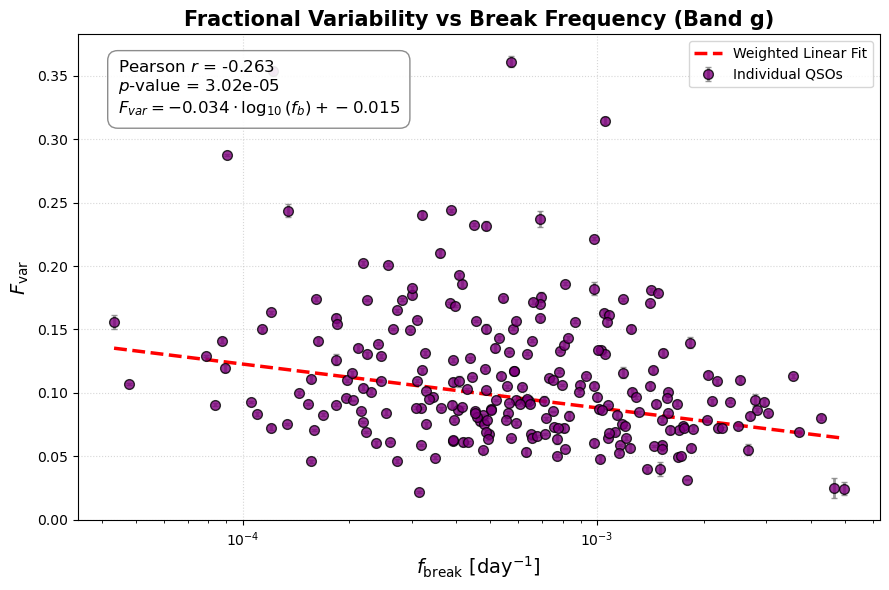

Sucesso! 245 objetos analisados com pesos.
Coeficiente Angular Ponderado: -0.034
P-value (Pearson): 3.02e-05


In [5]:
from scipy.optimize import curve_fit
from scipy.stats import pearsonr

# ============================================================================
# 6. INDIVIDUAL F_VAR vs F_BREAK PLOT (WLS - WEIGHTED FIT)
# ============================================================================

print("\nAjustando PSDs individuais para extrair f_break com pesos...")

individual_f_break = []
individual_f_var = []
individual_f_var_err = []

for i in tqdm(range(len(valid_data)), desc="Fitting Individual PSDs"):
    f_var_i = valid_data[i]['f_var']
    f_var_err_i = valid_data[i]['f_var_err']
    
    if np.isnan(f_var_i) or np.isnan(f_var_err_i):
        continue
        
    p_fit = binned_matrix_fft[i, :]
    valid = (~np.isnan(p_fit)) & (p_fit > 0)
    
    f_valid = bin_centers[valid]
    p_valid = p_fit[valid]
    
    if len(f_valid) > 10:
        log_p_valid = np.log10(p_valid)
        
        p0 = [np.max(log_p_valid), -3.0, 2.0, np.min(log_p_valid)]
        bounds = ([-10.0, -4.5, 0.0, -10.0], [10.0, -1.0, 4.0, 10.0])
        
        try:
            popt, _ = curve_fit(log_bending_power_law, f_valid, log_p_valid, p0=p0, bounds=bounds, maxfev=2000)
            log_f_break = popt[1]
            
            # Filtro de detecção real
            if log_f_break > -4.4 and log_f_break < -1.1:
                f_break = 10**log_f_break
                individual_f_break.append(f_break)
                individual_f_var.append(f_var_i)
                individual_f_var_err.append(f_var_err_i)
        except:
            pass

if len(individual_f_break) > 0:
    plt.figure(figsize=(9, 6))
    
    log_f_break_arr = np.log10(individual_f_break)
    f_var_arr = np.array(individual_f_var)
    f_var_err_arr = np.array(individual_f_var_err)
    
    # 1. Regressão Linear Ponderada (WLS) usando os erros fotométricos
    def linear_model(x, slope, intercept):
        return slope * x + intercept
        
    popt_lin, _ = curve_fit(linear_model, log_f_break_arr, f_var_arr, 
                            sigma=f_var_err_arr, absolute_sigma=True)
    w_slope, w_intercept = popt_lin
    
    # 2. Correlação de Pearson padrão para extrair o P-value
    r_value, p_value = pearsonr(log_f_break_arr, f_var_arr)
    
    # Gerar pontos para desenhar a reta
    x_fit_log = np.linspace(np.min(log_f_break_arr), np.max(log_f_break_arr), 100)
    y_fit = w_slope * x_fit_log + w_intercept
    x_fit_lin = 10**x_fit_log 
    
    # Plot dos pontos com barras de erro translúcidas
    plt.errorbar(individual_f_break, individual_f_var, yerr=individual_f_var_err, 
                 fmt='o', color='purple', alpha=0.8, ecolor='gray', elinewidth=2, capsize=2, 
                 markeredgecolor='k', markersize=7, label='Individual QSOs')
                 
    # Plot da reta ajustada com pesos
    plt.plot(x_fit_lin, y_fit, color='red', lw=2.5, ls='--', label='Weighted Linear Fit')
    
    plt.xscale('log')
    plt.xlabel(r"$f_{\rm{break}} \ [\rm{day}^{-1}]$", fontsize=14, fontweight='bold')
    plt.ylabel(r"$F_{\rm{var}}$", fontsize=14, fontweight='bold')
    plt.title(f"Fractional Variability vs Break Frequency (Band {band})", fontsize=15, fontweight='bold')
    
    stats_text = (f"Pearson $r$ = {r_value:.3f}\n"
                  f"$p$-value = {p_value:.2e}\n"
                  f"$F_{{var}} = {w_slope:.3f} \\cdot \\log_{{10}}(f_b) + {w_intercept:.3f}$")
    
    plt.text(0.05, 0.95, stats_text, transform=plt.gca().transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round,pad=0.6', facecolor='white', alpha=0.9, edgecolor='gray'))
             
    plt.legend(loc='upper right')
    plt.grid(True, ls=':', alpha=0.5)
    plt.tight_layout()
    
    out_file = os.path.join(plots_dir_base, f"fvar_vs_fbreak_individual_{band}_weighted_fit.png")
    plt.savefig(out_file, dpi=200)
    plt.show()
    
    print(f"Sucesso! {len(individual_f_break)} objetos analisados com pesos.")
    print(f"Coeficiente Angular Ponderado: {w_slope:.3f}")
    print(f"P-value (Pearson): {p_value:.2e}")
else:
    print("O modelo não encontrou joelhos reais para prosseguir com o ajuste.")


Gerando plot de Stacking Global com o painel superior de contagem de objetos...


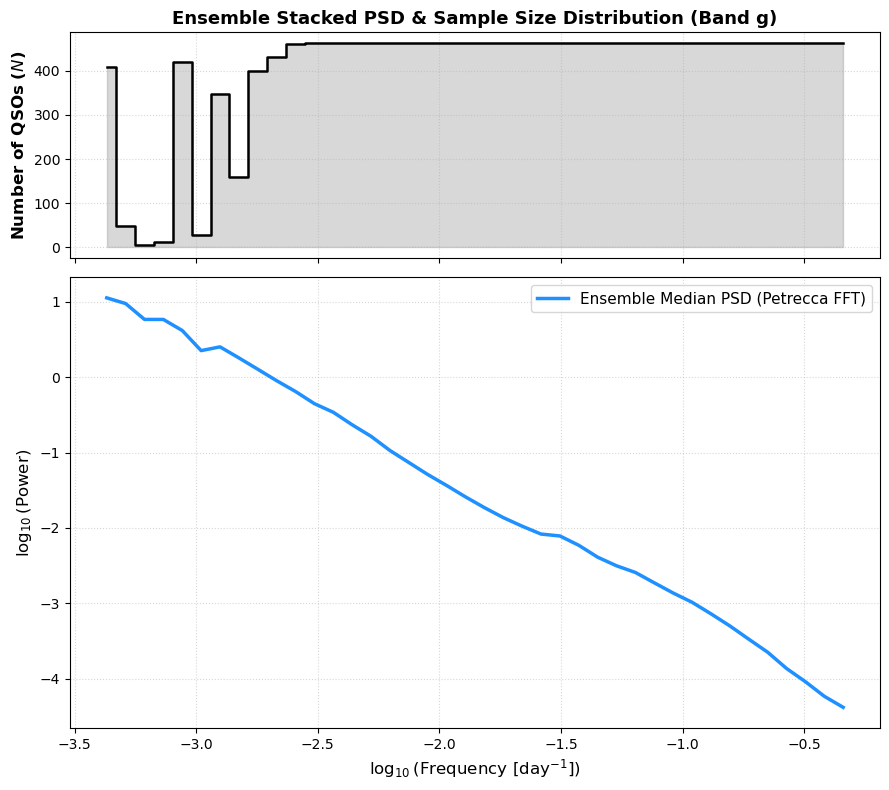

Gráfico com contagem de objetos salvo com sucesso em: plots_Petrecca_Analysis/stacked_global_with_n_objects_g.png


In [6]:
# ============================================================================
# 7. ENSEMBLE STACKED PSD WITH CONTRIBUTING OBJECTS COUNT PANEL
# ============================================================================

print("\nGerando plot de Stacking Global com o painel superior de contagem de objetos...")

# 1. Identificar quais bins possuem dados válidos (mínimo de 3 objetos para calcular mediana com segurança)
MIN_OBJS_GLOBAL = 3
valid_cols_mask = np.sum(~np.isnan(binned_matrix_fft), axis=0) >= MIN_OBJS_GLOBAL

# 2. Calcular a mediana global do ensemble e a contagem de objetos por bin
global_med_psd = np.full(N_bins, np.nan)
global_med_psd[valid_cols_mask] = np.nanmedian(binned_matrix_fft[:, valid_cols_mask], axis=0)

n_objs_per_bin = np.sum(~np.isnan(binned_matrix_fft), axis=0)

# 3. Filtrar máscaras finais para plotagem
plot_mask = valid_cols_mask & (global_med_psd > 0)

x_freq = bin_centers[plot_mask]
log_f = np.log10(x_freq)
log_p = np.log10(global_med_psd[plot_mask])
n_counts = n_objs_per_bin[plot_mask]

# 4. Criando a figura com 2 painéis verticais compartilhando o eixo X
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(9, 8), sharex=True, gridspec_kw={'height_ratios': [1, 2]})

# --- Painel Superior: Número de Objetos por Bin de Frequência ---
ax_top.plot(log_f, n_counts, drawstyle='steps-mid', color='black', lw=1.8)
ax_top.fill_between(log_f, n_counts, step='mid', color='gray', alpha=0.3)
ax_top.set_ylabel(r"Number of QSOs ($N$)", fontsize=12, fontweight='bold')
ax_top.set_title(f"Ensemble Stacked PSD & Sample Size Distribution (Band {band})", fontsize=13, fontweight='bold')
ax_top.grid(ls=':', alpha=0.5)

# --- Painel Inferior: PSD Global Stacked (Mediana via FFT) ---
ax_bottom.plot(log_f, log_p, color='dodgerblue', lw=2.5, label='Ensemble Median PSD (Petrecca FFT)')
ax_bottom.set_xlabel(r"$\log_{10}(\text{Frequency } [\text{day}^{-1}])$", fontsize=12, fontweight='bold')
ax_bottom.set_ylabel(r"$\log_{10}(\text{Power})$", fontsize=12, fontweight='bold')
ax_bottom.legend(loc='upper right', fontsize=11)
ax_bottom.grid(ls=':', alpha=0.5)

plt.tight_layout()
out_file = os.path.join(plots_dir_base, f"stacked_global_with_n_objects_{band}.png")
plt.savefig(out_file, dpi=200)
plt.show()

print(f"Gráfico com contagem de objetos salvo com sucesso em: {out_file}")